# NASA GAMES Mini Demo: Space Weather to Survivability

This notebook is the transparent computational source behind the mini GitHub demonstration.

**Workflow:** NASA measurements → calculate/plot → interpret → survivability model → mission decision

The NASA/SPDF OMNI2 interval is measured upstream near Earth. The operational thresholds and survivability coefficients used below are educational assumptions, not NASA flight rules.


## 1. Space-weather physics

The solar-wind dynamic pressure is

\[
P_{\mathrm{dyn}} = n_p m_p V_{\mathrm{sw}}^2 .
\]

The bundled dataset already contains archived flow pressure together with proton density, solar-wind speed, and magnetic-field magnitude.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("..") / "data" / "NASA_OMNI2_2017-09-06_07.csv"
df = pd.read_csv(DATA)
df["Time"] = pd.to_datetime(df["Time"])
df.head()

,Time,B_nT,Proton_Density_cm-3,Flow_Speed_km-s,Flow_Pressure_nPa
0,2017-09-06 00:00:00+00:00,4.1,4.1,466,1.54
1,2017-09-06 01:00:00+00:00,4.4,3.6,475,1.41
2,2017-09-06 02:00:00+00:00,4.8,2.7,467,1.07
3,2017-09-06 03:00:00+00:00,4.4,3.8,479,1.56
4,2017-09-06 04:00:00+00:00,3.2,6.3,484,2.52


In [2]:
summary = {
    "records": len(df),
    "peak_flow_pressure_nPa": df["Flow_Pressure_nPa"].max(),
    "mean_flow_pressure_nPa": df["Flow_Pressure_nPa"].mean(),
    "peak_speed_km_s": df["Flow_Speed_km-s"].max(),
    "peak_B_nT": df["B_nT"].max(),
}
summary

{'records': 33,
 'peak_flow_pressure_nPa': np.float64(8.68),
 'mean_flow_pressure_nPa': np.float64(2.633030303030303),
 'peak_speed_km_s': np.int64(581),
 'peak_B_nT': np.float64(14.4)}

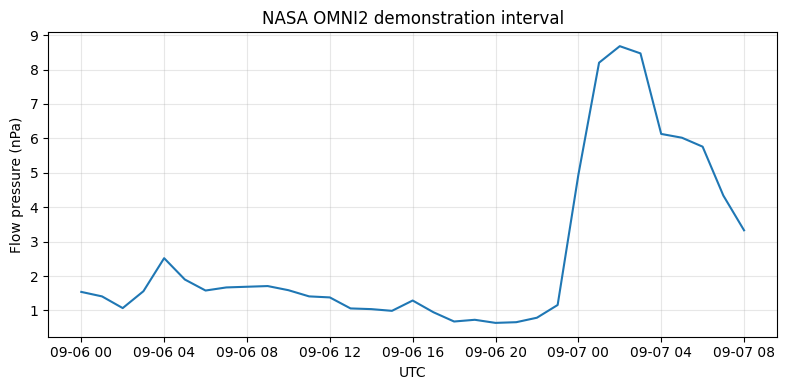

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(df["Time"], df["Flow_Pressure_nPa"])
plt.xlabel("UTC")
plt.ylabel("Flow pressure (nPa)")
plt.title("NASA OMNI2 demonstration interval")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Radiation / survivability connection

Cumulative exposure is represented by

\[
D(t)=\int_0^t \dot D(t')\,dt' .
\]

For this mini demonstration, the analyzed space-weather state is converted to an **educational** hazard index. A shielding factor is then applied before the cumulative index is propagated into a teaching system-health model.


In [4]:
peak_pressure = summary["peak_flow_pressure_nPa"]
peak_speed = summary["peak_speed_km_s"]

if peak_pressure >= 6 or peak_speed >= 550:
    eva_status, hazard = "NO-GO", 1.0
elif peak_pressure >= 3 or peak_speed >= 475:
    eva_status, hazard = "CAUTION", 0.6
else:
    eva_status, hazard = "GO", 0.25

incident_rate = 0.2 + 0.9 * hazard
shielding_factor = 0.55
shielded_rate = incident_rate * shielding_factor

hours = np.arange(0, 13)
cumulative_dose_index = shielded_rate * hours
health = max(0.0, 100.0 - 0.8 * cumulative_dose_index[-1])

recommendation = {
    "NO-GO": "Enter Storm Shelter",
    "CAUTION": "Delay EVA",
    "GO": "Continue EVA"
}[eva_status]

{
    "EVA status": eva_status,
    "12 h cumulative dose index": cumulative_dose_index[-1],
    "system health (%)": health,
    "recommended teaching action": recommendation,
}

{'EVA status': 'NO-GO',
 '12 h cumulative dose index': np.float64(7.260000000000002),
 'system health (%)': np.float64(94.192),
 'recommended teaching action': 'Enter Storm Shelter'}

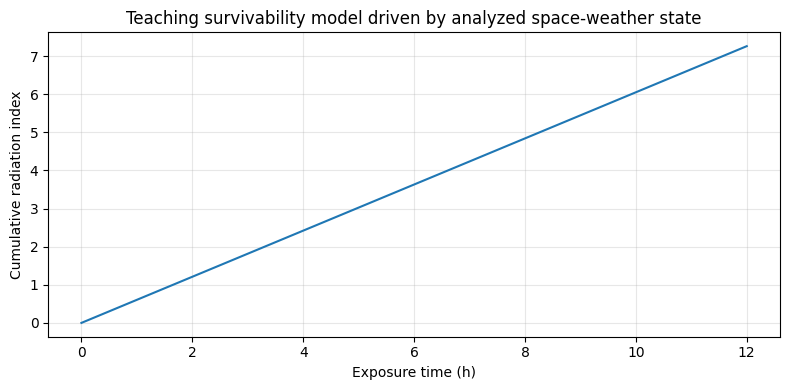

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(hours, cumulative_dose_index)
plt.xlabel("Exposure time (h)")
plt.ylabel("Cumulative radiation index")
plt.title("Teaching survivability model driven by analyzed space-weather state")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Mission decision

The important educational result is not only the plotted number. The student must explain how the measured data and physical model support the operational choice.

**Decision options:** Continue EVA · Delay EVA · Enter Storm Shelter
